In [2]:
import pandas as pd

df = pd.read_csv("../data/raw/AQI.csv")

C:\Users\Sarosh\AppData\Local\Temp\ipykernel_17056\888681790.py:3: DtypeWarning: Columns (0: AQI_Bucket) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/raw/AQI.csv")


In [3]:
print(df.head())

  StationId             Datetime  PM2.5    PM10    NO    NO2    NOx    NH3  \
0     AP001  2017-11-24 17:00:00  60.50   98.00  2.35  30.80  18.25   8.50   
1     AP001  2017-11-24 18:00:00  65.50  111.25  2.70  24.20  15.07   9.77   
2     AP001  2017-11-24 19:00:00  80.00  132.00  2.10  25.18  15.15  12.02   
3     AP001  2017-11-24 20:00:00  81.50  133.25  1.95  16.25  10.23  11.58   
4     AP001  2017-11-24 21:00:00  75.25  116.00  1.43  17.48  10.43  12.03   

    CO    SO2      O3  Benzene  Toluene  Xylene  AQI AQI_Bucket  
0  0.1  11.85  126.40      0.1     6.10    0.10  NaN        NaN  
1  0.1  13.17  117.12      0.1     6.25    0.15  NaN        NaN  
2  0.1  12.08   98.98      0.2     5.98    0.18  NaN        NaN  
3  0.1  10.47  112.20      0.2     6.72    0.10  NaN        NaN  
4  0.1   9.12  106.35      0.2     5.75    0.08  NaN        NaN  


In [4]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 2589083 entries, 0 to 2589082
Data columns (total 16 columns):
 #   Column      Dtype  
---  ------      -----  
 0   StationId   str    
 1   Datetime    str    
 2   PM2.5       float64
 3   PM10        float64
 4   NO          float64
 5   NO2         float64
 6   NOx         float64
 7   NH3         float64
 8   CO          float64
 9   SO2         float64
 10  O3          float64
 11  Benzene     float64
 12  Toluene     float64
 13  Xylene      float64
 14  AQI         float64
 15  AQI_Bucket  str    
dtypes: float64(13), str(3)
memory usage: 316.1 MB
None


In [5]:
print(df.columns)

Index(['StationId', 'Datetime', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3',
       'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket'],
      dtype='str')


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2589083 entries, 0 to 2589082
Data columns (total 16 columns):
 #   Column      Dtype  
---  ------      -----  
 0   StationId   str    
 1   Datetime    str    
 2   PM2.5       float64
 3   PM10        float64
 4   NO          float64
 5   NO2         float64
 6   NOx         float64
 7   NH3         float64
 8   CO          float64
 9   SO2         float64
 10  O3          float64
 11  Benzene     float64
 12  Toluene     float64
 13  Xylene      float64
 14  AQI         float64
 15  AQI_Bucket  str    
dtypes: float64(13), str(3)
memory usage: 316.1 MB


In [7]:
print(df["Datetime"].min())
print(df["Datetime"].max())

2015-01-01 01:00:00
2020-07-01 00:00:00


In [8]:
df.columns

Index(['StationId', 'Datetime', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3',
       'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket'],
      dtype='str')

In [9]:
df.isnull().sum()

StationId           0
Datetime            0
PM2.5          647689
PM10          1119252
NO             553711
NO2            528973
NOx            490808
NH3           1236618
CO             499302
SO2            742737
O3             725973
Benzene        861579
Toluene       1042366
Xylene        2075104
AQI            570190
AQI_Bucket     570190
dtype: int64

In [10]:
df["Datetime"] = pd.to_datetime(df["Datetime"])

In [11]:
df = df.dropna(subset=["AQI"])

In [12]:
print(df.shape)

(2018893, 16)


In [13]:
station_counts = df["StationId"].value_counts()

print(station_counts.head(20))

StationId
DL031    39207
UP012    39176
UP014    38890
TN001    38698
KA009    36580
KA003    36255
DL002    35979
DL021    35903
DL028    33885
TN004    33018
TN003    32904
DL019    31688
TG005    31592
GJ001    30921
TG004    30800
HR014    30422
BR007    30297
DL013    28795
TG003    28369
DL007    27851
Name: count, dtype: int64


In [14]:
station_df = df[df["StationId"] == "DL031"].copy()
station_df = station_df[["Datetime", "AQI"]]


In [15]:
#Prophet With Feature Selection (Adding Pollutants)

station_v2 = df[df["StationId"] == "DL031"].copy()
station_v2 = station_v2[
    [
        "Datetime",
        "AQI",
        "PM10",
        "PM2.5",
        "CO",
        "NO2"
    ]
]
station_v2 = station_v2.rename(
    columns={
        "Datetime":"ds",
        "AQI":"y"
    }
)
station_v2 = station_v2.sort_values("ds")

In [16]:
station_v2 = station_v2.ffill()
station_v2 = station_v2.bfill()

In [17]:
station_v2.isnull().sum()


ds       0
y        0
PM10     0
PM2.5    0
CO       0
NO2      0
dtype: int64

In [18]:
#Training new Prophet
train_size = int(len(station_v2) * 0.8)

train = station_v2.iloc[:train_size]

test = station_v2.iloc[train_size:]

In [19]:
#new Prophet

from prophet import Prophet

model_v2 = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=True
)

model_v2.add_regressor("PM10")
model_v2.add_regressor("PM2.5")
model_v2.add_regressor("CO")
model_v2.add_regressor("NO2")

In [20]:
#new Prp

model_v2.fit(train)

10:51:26 - cmdstanpy - INFO - Chain [1] start processing
10:51:41 - cmdstanpy - INFO - Chain [1] done processing


In [21]:
station_df.head()

,Datetime,AQI
1000329,2015-04-05 02:00:00,399.0
1000330,2015-04-05 03:00:00,359.0
1000331,2015-04-05 04:00:00,359.0
1000332,2015-04-05 05:00:00,359.0
1000333,2015-04-05 06:00:00,359.0


In [22]:
station_df.columns = ["ds", "y"]
station_df = station_df.sort_values("ds")

In [23]:
station_df.info()

<class 'pandas.DataFrame'>
Index: 39207 entries, 1000329 to 1046263
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   ds      39207 non-null  datetime64[us]
 1   y       39207 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 918.9 KB


In [24]:
station_df.head()

,ds,y
1000329,2015-04-05 02:00:00,399.0
1000330,2015-04-05 03:00:00,359.0
1000331,2015-04-05 04:00:00,359.0
1000332,2015-04-05 05:00:00,359.0
1000333,2015-04-05 06:00:00,359.0


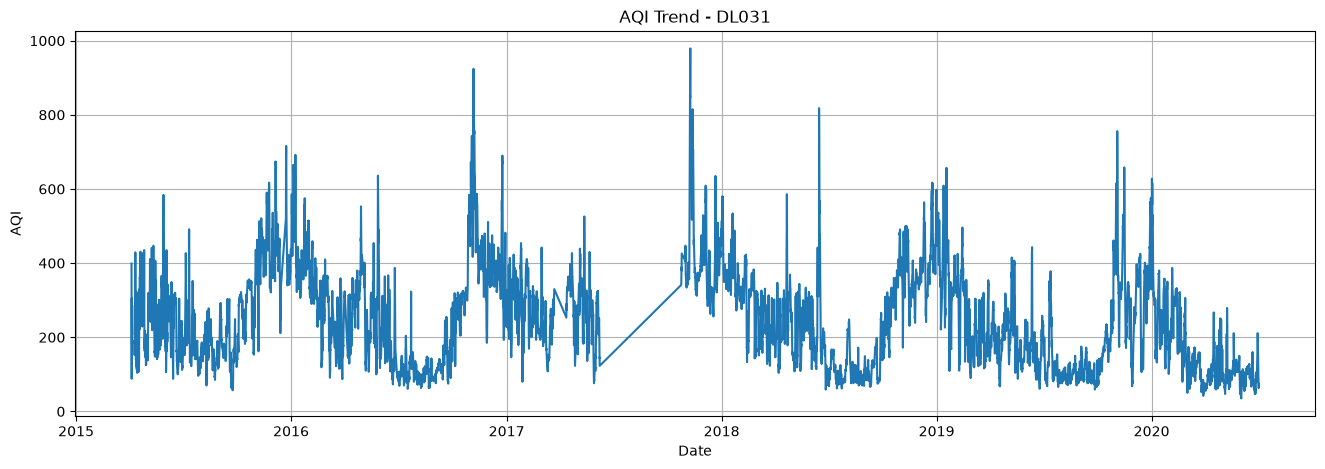

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16,5))

plt.plot(station_df["ds"], station_df["y"])

plt.title("AQI Trend - DL031")

plt.xlabel("Date")

plt.ylabel("AQI")

plt.grid(True)

plt.show()

In [26]:
print(station_df["ds"].diff().value_counts().head(10))

ds
0 days 01:00:00    39128
1 days 00:00:00        6
0 days 22:00:00        5
1 days 02:00:00        5
0 days 19:00:00        4
0 days 17:00:00        4
1 days 01:00:00        3
0 days 18:00:00        3
1 days 05:00:00        3
2 days 07:00:00        2
Name: count, dtype: int64


In [27]:
train_size = int(len(station_df) * 0.8)

train = station_df.iloc[:train_size]

test = station_df.iloc[train_size:]

print("Training Shape :", train.shape)
print("Testing Shape :", test.shape)

Training Shape : (31365, 2)
Testing Shape : (7842, 2)


In [28]:
from prophet import Prophet

In [29]:
model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=True
)

model

In [30]:
model.fit(train)

10:51:43 - cmdstanpy - INFO - Chain [1] start processing
10:51:57 - cmdstanpy - INFO - Chain [1] done processing


In [31]:
future = model.make_future_dataframe(
    periods=len(test),
    freq="h"
)

future.tail()

,ds
39202,2020-06-26 15:00:00
39203,2020-06-26 16:00:00
39204,2020-06-26 17:00:00
39205,2020-06-26 18:00:00
39206,2020-06-26 19:00:00


In [32]:
forecast = model.predict(future)

forecast.head()

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,daily,...,weekly,weekly_lower,weekly_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2015-04-05 02:00:00,270.484865,133.559419,327.068004,270.484865,270.484865,-35.222660,-35.222660,-35.222660,0.055454,...,3.994789,3.994789,3.994789,-39.272904,-39.272904,-39.272904,0.0,0.0,0.0,235.262205
1,2015-04-05 03:00:00,270.503060,136.928823,327.892273,270.503060,270.503060,-35.722802,-35.722802,-35.722802,0.183592,...,3.305812,3.305812,3.305812,-39.212206,-39.212206,-39.212206,0.0,0.0,0.0,234.780257
2,2015-04-05 04:00:00,270.521254,132.939520,333.160123,270.521254,270.521254,-36.278059,-36.278059,-36.278059,0.282149,...,2.591104,2.591104,2.591104,-39.151312,-39.151312,-39.151312,0.0,0.0,0.0,234.243195
3,2015-04-05 05:00:00,270.539449,128.797695,335.809565,270.539449,270.539449,-36.879380,-36.879380,-36.879380,0.356834,...,1.854007,1.854007,1.854007,-39.090222,-39.090222,-39.090222,0.0,0.0,0.0,233.660068
4,2015-04-05 06:00:00,270.557643,128.550057,323.368721,270.557643,270.557643,-37.569167,-37.569167,-37.569167,0.361643,...,1.098126,1.098126,1.098126,-39.028936,-39.028936,-39.028936,0.0,0.0,0.0,232.988476


In [33]:
forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail()

,ds,yhat,yhat_lower,yhat_upper
39202,2020-06-26 15:00:00,149.740853,-155.098402,481.167643
39203,2020-06-26 16:00:00,149.682416,-146.520873,485.580053
39204,2020-06-26 17:00:00,149.666087,-150.806928,486.802478
39205,2020-06-26 18:00:00,149.622572,-145.115833,486.955751
39206,2020-06-26 19:00:00,149.478765,-159.293466,481.523887


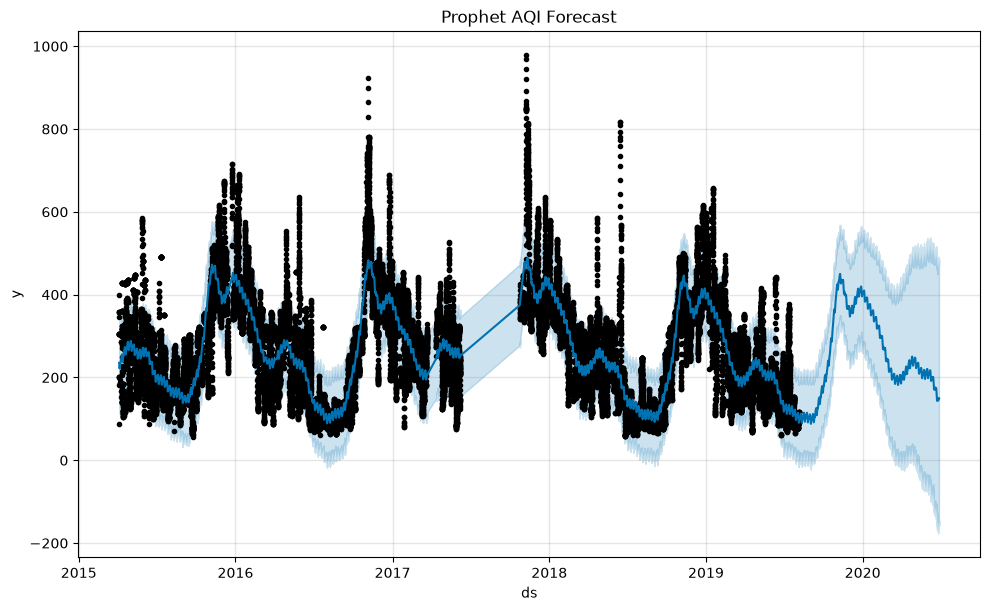

In [34]:
fig = model.plot(forecast)
plt.title("Prophet AQI Forecast")
plt.show()

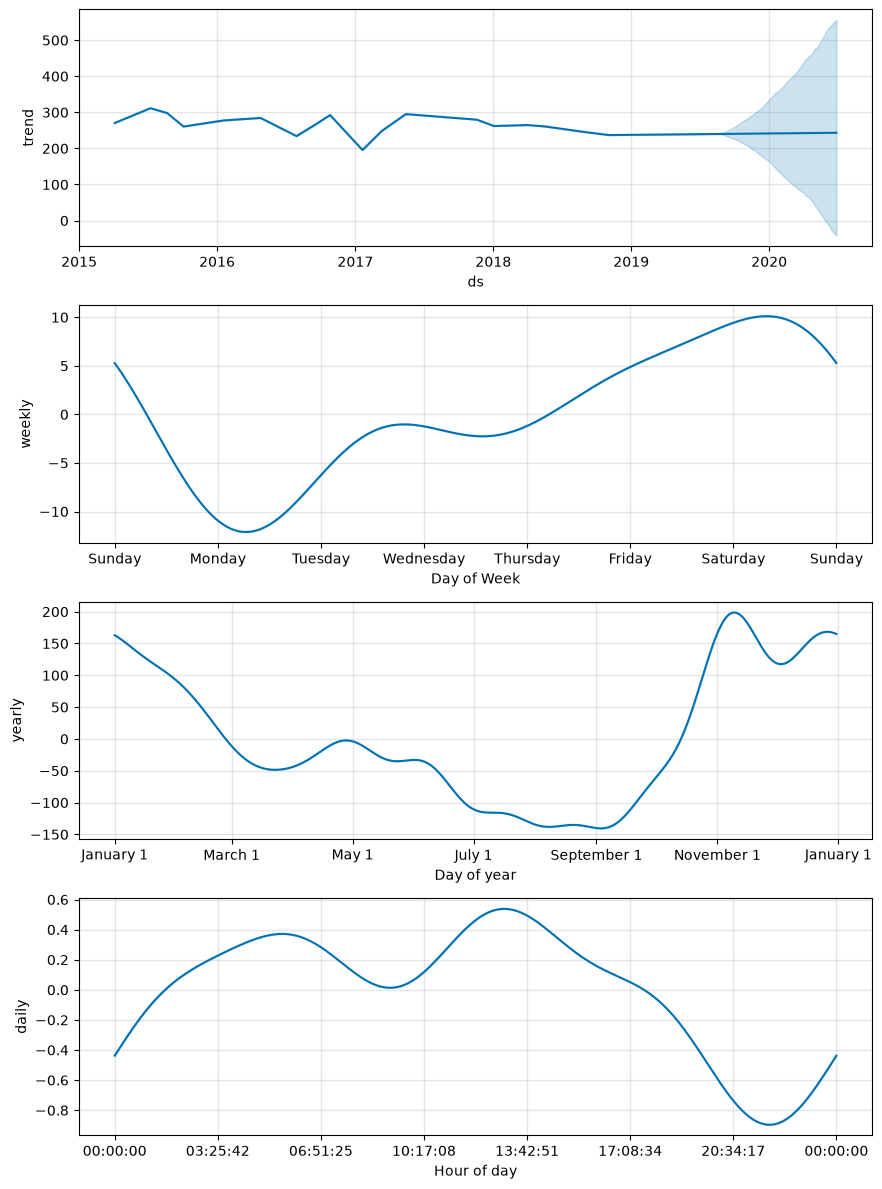

In [35]:
fig2 = model.plot_components(forecast)
plt.show()

In [36]:
from sklearn.metrics import mean_squared_error
import numpy as np

predictions = forecast["yhat"].tail(len(test)).values

actual = test["y"].values

rmse = np.sqrt(mean_squared_error(actual, predictions))

print(f"RMSE: {rmse:.2f}")

RMSE: 106.75


In [37]:
import matplotlib.pyplot as plt

corr = df[
    [
        "AQI",
        "PM2.5",
        "PM10",
        "NO",
        "NO2",
        "NOx",
        "NH3",
        "CO",
        "SO2",
        "O3",
        "Benzene",
        "Toluene",
        "Xylene",
    ]
].corr()

corr["AQI"].sort_values(ascending=False)

AQI        1.000000
PM10       0.756797
PM2.5      0.658323
CO         0.409972
NO2        0.401429
NH3        0.389390
NOx        0.364035
NO         0.318944
SO2        0.310280
Toluene    0.253566
O3         0.132111
Benzene    0.107283
Xylene     0.106220
Name: AQI, dtype: float64

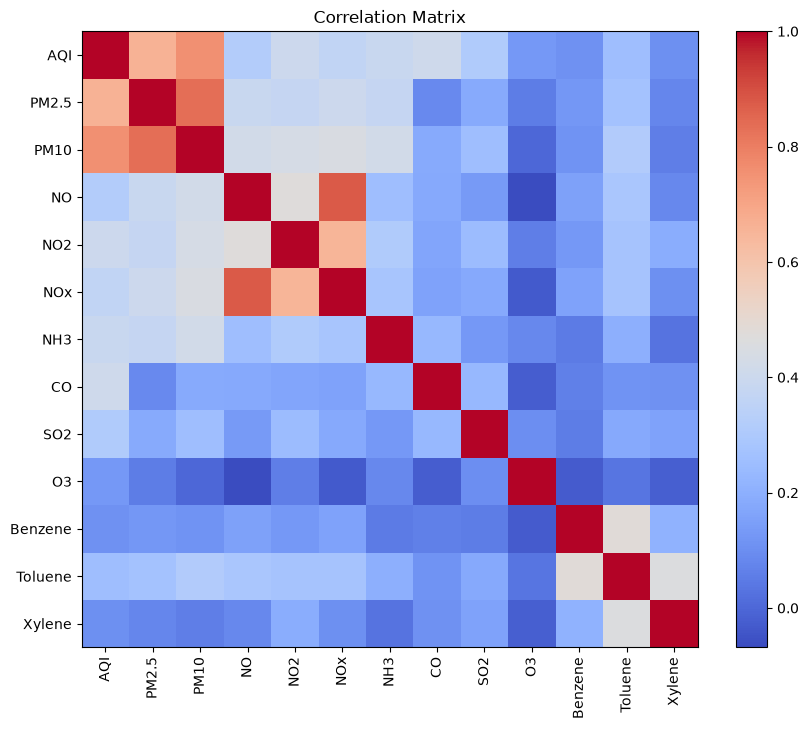

In [38]:
plt.figure(figsize=(10,8))

plt.imshow(corr, cmap="coolwarm")

plt.colorbar()

plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)

plt.yticks(range(len(corr.columns)), corr.columns)

plt.title("Correlation Matrix")

plt.show()

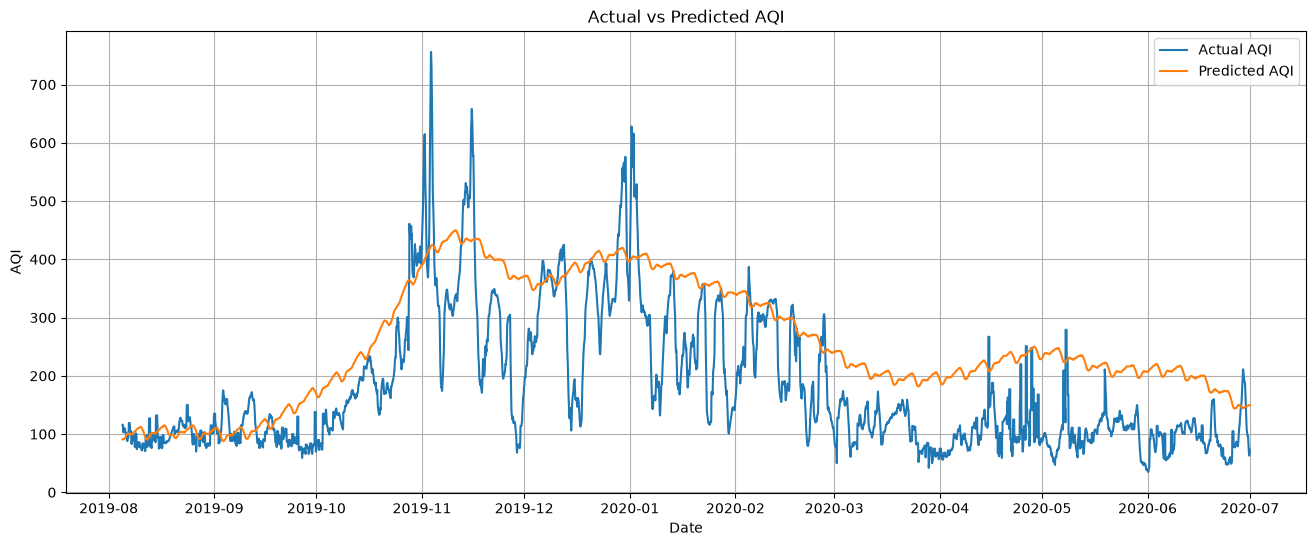

In [39]:
comparison = test.copy()

comparison["Predicted"] = predictions

plt.figure(figsize=(16,6))

plt.plot(comparison["ds"], comparison["y"], label="Actual AQI")

plt.plot(comparison["ds"], comparison["Predicted"], label="Predicted AQI")

plt.title("Actual vs Predicted AQI")

plt.xlabel("Date")

plt.ylabel("AQI")

plt.legend()

plt.grid(True)

plt.show()

# Persistence Baseline

In [40]:
baseline = test.copy()

In [41]:
baseline["prediction"] = baseline["y"].shift(1)

In [42]:
baseline = baseline.dropna()

In [43]:
from sklearn.metrics import mean_squared_error
import numpy as np

baseline_rmse = np.sqrt(
    mean_squared_error(
        baseline["y"],
        baseline["prediction"]
    )
)

print("Persistence RMSE:", baseline_rmse)

Persistence RMSE: 7.333328502469878


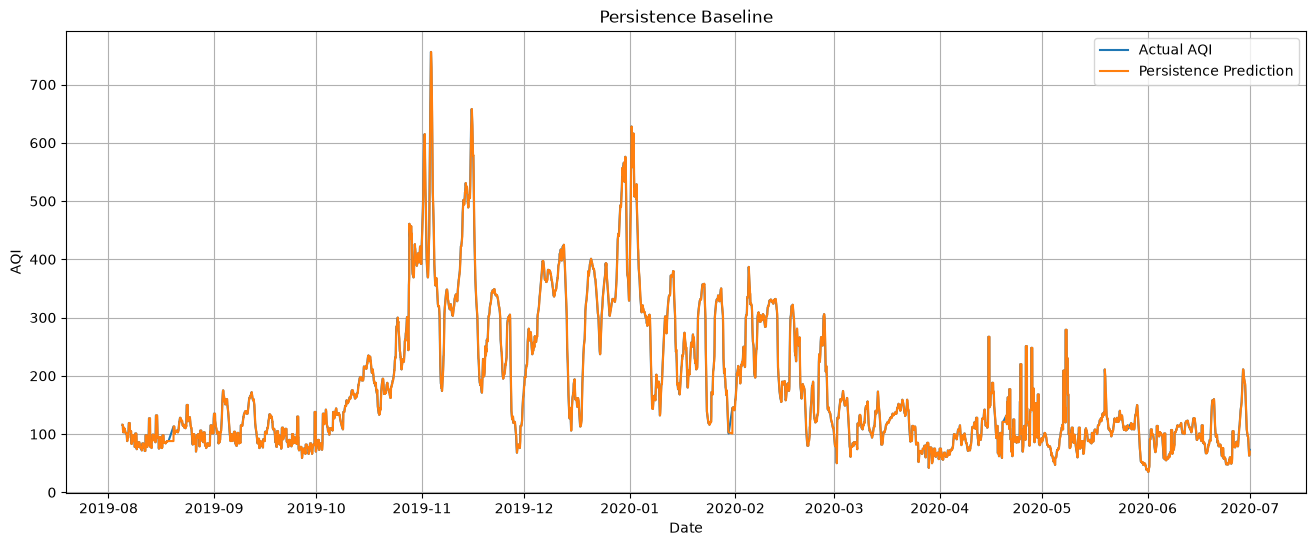

In [44]:
plt.figure(figsize=(16,6))

plt.plot(
    baseline["ds"],
    baseline["y"],
    label="Actual AQI"
)

plt.plot(
    baseline["ds"],
    baseline["prediction"],
    label="Persistence Prediction"
)

plt.title("Persistence Baseline")

plt.xlabel("Date")

plt.ylabel("AQI")

plt.legend()

plt.grid(True)

plt.show()

In [45]:
results = {
    "Model": [
        "Persistence",
        "Prophet"
    ],
    "RMSE": [
        baseline_rmse,
        rmse
    ]
}

import pandas as pd

results_df = pd.DataFrame(results)

results_df

,Model,RMSE
0,Persistence,7.333329
1,Prophet,106.753904


In [46]:
from prophet.serialize import model_to_json

with open("../app/models/prophet/DL031.json", "w") as fout:
    fout.write(model_to_json(model))